# Telco Customer Churn — end-to-end prediction

**Goal:** predict which customers will cancel so the retention team can step in first, and explain *why* they leave.
Data: IBM Telco Customer Churn sample (7,043 customers, 21 columns).

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
warnings.filterwarnings("ignore")
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from churn import load_raw, clean, engineer, split_xy, build_models, RANDOM_STATE
IMG, OUT = ROOT / "images", ROOT / "outputs"; IMG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)
raw = load_raw(); print(raw.shape); raw.head()

(7043, 21)


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. Data quality

In [2]:
print("Duplicate IDs:", raw.customerID.duplicated().sum())
blank_tc = (raw.TotalCharges.str.strip() == "").sum()
print("Blank TotalCharges:", blank_tc, "-> all have tenure =", raw.loc[raw.TotalCharges.str.strip()=="", "tenure"].unique())
df = engineer(clean(raw))
print(f"Churn rate: {df.Churn.mean():.1%}  ({df.Churn.sum():,} of {len(df):,})")

Duplicate IDs: 0
Blank TotalCharges: 11 -> all have tenure = [0]
Churn rate: 26.5%  (1,869 of 7,043)


## 2. Exploratory analysis — who churns?

In [3]:
def rate(col): return df.groupby(col)["Churn"].mean().mul(100).round(1)
for c in ["Contract", "tenure_group", "InternetService", "PaymentMethod", "TechSupport", "SeniorCitizen", "PaperlessBilling"]:
    print(rate(c).to_string(), "\n")

Contract
Month-to-month    42.7
One year          11.3
Two year           2.8 

tenure_group
0-12m     47.4
13-24m    28.7
25-48m    20.4
49-72m     9.5 

InternetService
DSL            19.0
Fiber optic    41.9
No              7.4 

PaymentMethod
Bank transfer (automatic)    16.7
Credit card (automatic)      15.2
Electronic check             45.3
Mailed check                 19.1 

TechSupport
No                     41.6
No internet service     7.4
Yes                    15.2 

SeniorCitizen
No     23.6
Yes    41.7 

PaperlessBilling
No     16.3
Yes    33.6 



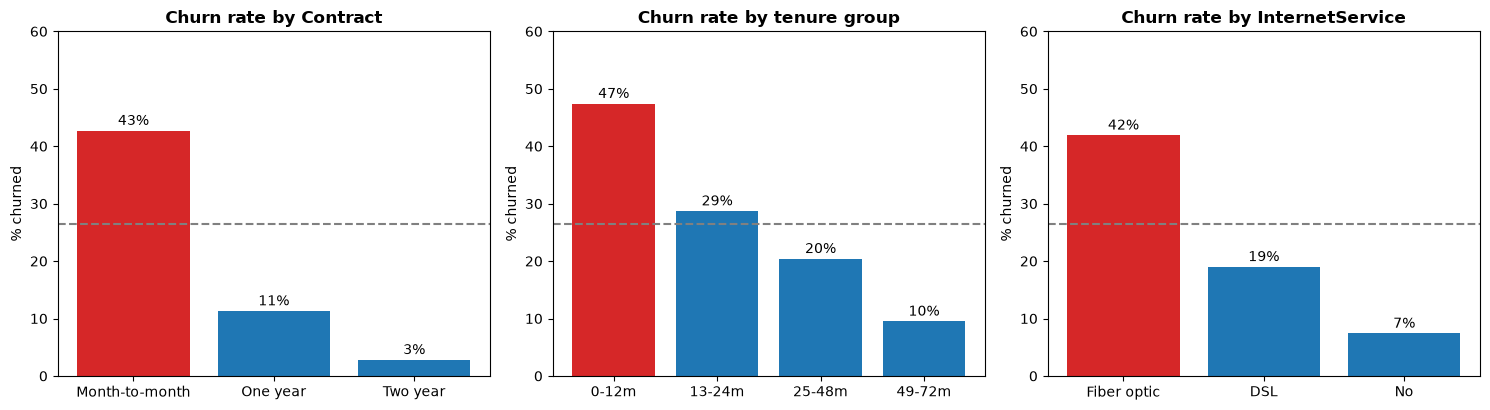

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, col, order in [(axes[0], "Contract", ["Month-to-month", "One year", "Two year"]),
                       (axes[1], "tenure_group", ["0-12m", "13-24m", "25-48m", "49-72m"]),
                       (axes[2], "InternetService", ["Fiber optic", "DSL", "No"])]:
    r = rate(col).reindex(order)
    ax.bar(r.index, r.values, color=["#d62728" if v > 30 else "#1f77b4" for v in r.values])
    for i, v in enumerate(r.values): ax.text(i, v + 1, f"{v:.0f}%", ha="center")
    ax.set_title(f"Churn rate by {col.replace('_', ' ')}", fontweight="bold"); ax.set_ylim(0, 60); ax.set_ylabel("% churned")
axes[0].axhline(df.Churn.mean()*100, ls="--", c="grey"); axes[1].axhline(df.Churn.mean()*100, ls="--", c="grey"); axes[2].axhline(df.Churn.mean()*100, ls="--", c="grey")
plt.tight_layout(); plt.savefig(IMG / "eda_churn_drivers.png", dpi=130); plt.show()

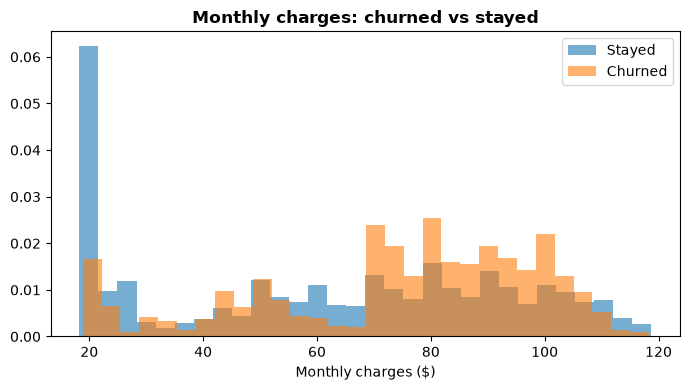

,tenure,MonthlyCharges,num_addon_services
Churn,,,
0,38.0,64.425,2.0
1,10.0,79.650,2.0


In [5]:
fig, ax = plt.subplots(figsize=(7, 4))
for v, lab in [(0, "Stayed"), (1, "Churned")]:
    ax.hist(df.loc[df.Churn == v, "MonthlyCharges"], bins=30, alpha=.6, density=True, label=lab)
ax.set_xlabel("Monthly charges ($)"); ax.set_title("Monthly charges: churned vs stayed", fontweight="bold"); ax.legend()
plt.tight_layout(); plt.show()
df.groupby("Churn")[["tenure", "MonthlyCharges", "num_addon_services"]].median()

## 3. Feature engineering
Added: `num_addon_services` (count of 6 add-ons), `tenure_group`, `avg_monthly_spend` (TotalCharges / tenure), `is_month_to_month`, `auto_pay`.

## 4. Modelling — Logistic Regression vs Gradient Boosting
Stratified 80/20 split; model selection by 5-fold CV ROC-AUC on the training set only.

In [6]:
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score, roc_curve, average_precision_score, precision_score, recall_score, f1_score, confusion_matrix
X, y = split_xy(df)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
cv = StratifiedKFold(5, shuffle=True, random_state=RANDOM_STATE)
models, probs, rows = build_models(X), {}, []
for name, pipe in models.items():
    auc_cv = cross_val_score(pipe, X_tr, y_tr, cv=cv, scoring="roc_auc")
    pipe.fit(X_tr, y_tr); p = pipe.predict_proba(X_te)[:, 1]; probs[name] = p; pred = (p >= .5).astype(int)
    rows.append(dict(model=name, cv_auc=auc_cv.mean(), cv_auc_std=auc_cv.std(), test_auc=roc_auc_score(y_te, p),
                     test_pr_auc=average_precision_score(y_te, p), precision=precision_score(y_te, pred),
                     recall=recall_score(y_te, pred), f1=f1_score(y_te, pred)))
res = pd.DataFrame(rows).round(3); res.to_csv(OUT / "model_comparison.csv", index=False); res

,model,cv_auc,cv_auc_std,test_auc,test_pr_auc,precision,recall,f1
0,Logistic Regression,0.846,0.011,0.842,0.637,0.653,0.519,0.578
1,Gradient Boosting,0.847,0.012,0.841,0.646,0.655,0.508,0.572


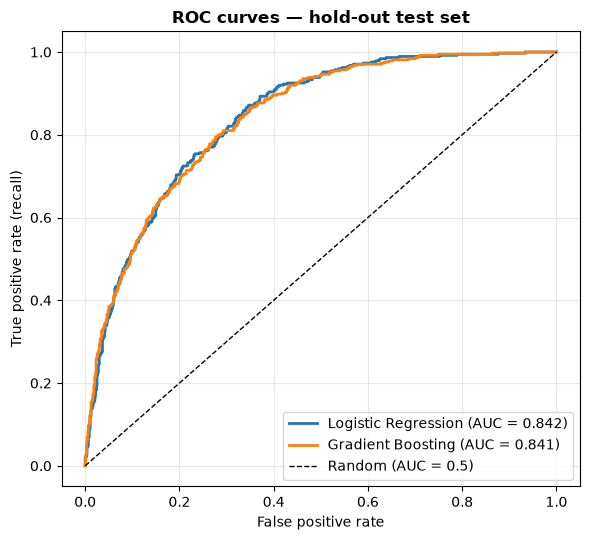

In [7]:
fig, ax = plt.subplots(figsize=(6, 5.5))
for name, p in probs.items():
    fpr, tpr, _ = roc_curve(y_te, p); ax.plot(fpr, tpr, lw=2, label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")
ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random (AUC = 0.5)")
ax.set_xlabel("False positive rate"); ax.set_ylabel("True positive rate (recall)")
ax.set_title("ROC curves — hold-out test set", fontweight="bold"); ax.legend(loc="lower right"); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(IMG / "roc_curves.png", dpi=130); plt.show()

### Choosing a decision threshold
At 0.5 the models catch only about half of churners. Missing a churner usually costs more than an unneeded retention offer, so we look at lower thresholds.

In [8]:
best = res.sort_values("cv_auc", ascending=False).iloc[0]["model"]; p = probs[best]
thr = pd.DataFrame([dict(threshold=t, precision=precision_score(y_te, p >= t), recall=recall_score(y_te, p >= t),
                         f1=f1_score(y_te, p >= t), flagged_pct=(p >= t).mean()*100) for t in [.2,.25,.3,.35,.4,.5]]).round(3)
thr.to_csv(OUT / "threshold_tradeoff.csv", index=False); print("Model:", best); thr

Model: Gradient Boosting


,threshold,precision,recall,f1,flagged_pct
0,0.20,0.481,0.829,0.609,45.706
1,0.25,0.509,0.791,0.619,41.306
2,0.30,0.524,0.738,0.613,37.402
3,0.35,0.554,0.690,0.614,33.073
4,0.40,0.594,0.636,0.614,28.460
5,0.50,0.655,0.508,0.572,20.582


In [9]:
tn, fp, fn, tp = confusion_matrix(y_te, p >= .3).ravel()
print(f"Threshold 0.30 -> TP {tp}, FP {fp}, FN {fn}, TN {tn}")

Threshold 0.30 -> TP 276, FP 251, FN 98, TN 784


### Gains: how many churners does the retention team reach?

Top 10% highest-risk customers contain 29% of all churners (lift 2.9x)
Top 20% highest-risk customers contain 49% of all churners (lift 2.4x)
Top 30% highest-risk customers contain 65% of all churners (lift 2.2x)
Top 40% highest-risk customers contain 78% of all churners (lift 1.9x)


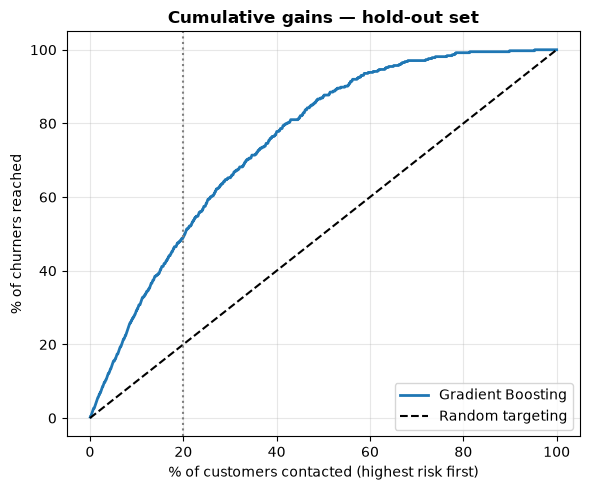

In [10]:
order = np.argsort(-p); cum = np.cumsum(y_te.values[order]) / y_te.sum(); pct = np.arange(1, len(p)+1) / len(p)
gains = {k: cum[int(k/100*len(p)) - 1] for k in (10, 20, 30, 40)}
for k, v in gains.items(): print(f"Top {k}% highest-risk customers contain {v:.0%} of all churners (lift {v/(k/100):.1f}x)")
fig, ax = plt.subplots(figsize=(6, 5)); ax.plot(pct*100, cum*100, lw=2, label=best); ax.plot([0,100],[0,100],"k--",label="Random targeting")
ax.axvline(20, c="grey", ls=":"); ax.set_xlabel("% of customers contacted (highest risk first)"); ax.set_ylabel("% of churners reached")
ax.set_title("Cumulative gains — hold-out set", fontweight="bold"); ax.legend(); ax.grid(alpha=.3)
plt.tight_layout(); plt.savefig(IMG / "gains_chart.png", dpi=130); plt.show()

## 5. Explainability — what drives churn?

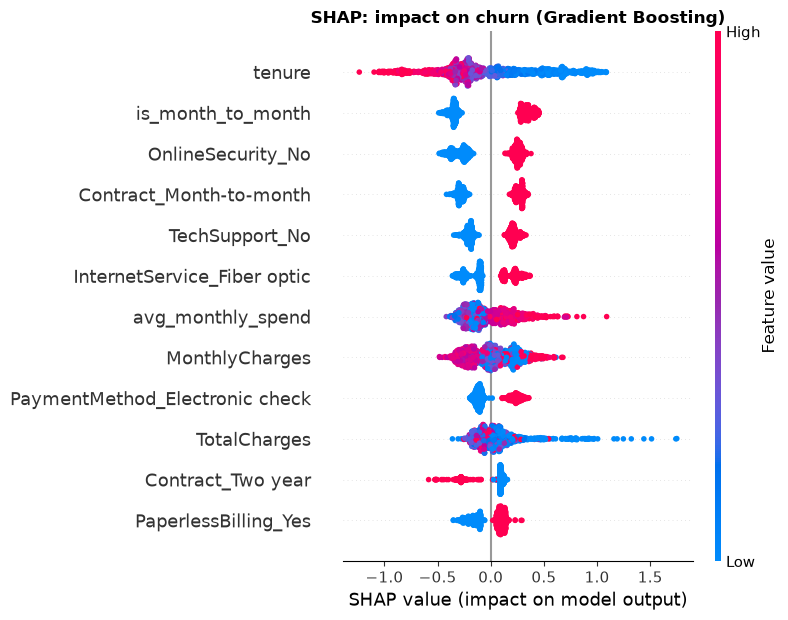

tenure                            0.3863
is_month_to_month                 0.3484
OnlineSecurity_No                 0.2766
Contract_Month-to-month           0.2756
TechSupport_No                    0.2091
InternetService_Fiber optic       0.1913
avg_monthly_spend                 0.1810
MonthlyCharges                    0.1802
PaymentMethod_Electronic check    0.1576
TotalCharges                      0.1449
dtype: float64

In [11]:
import shap
gb = models["Gradient Boosting"]
Xt = gb.named_steps["prep"].transform(X_te)
names = [n.split("__", 1)[1] for n in gb.named_steps["prep"].get_feature_names_out()]
sv = shap.TreeExplainer(gb.named_steps["model"]).shap_values(Xt)
plt.figure(); shap.summary_plot(sv, pd.DataFrame(Xt, columns=names), max_display=12, show=False)
plt.title("SHAP: impact on churn (Gradient Boosting)", fontweight="bold"); plt.tight_layout()
plt.savefig(IMG / "shap_summary.png", dpi=130, bbox_inches="tight"); plt.show()
imp = pd.Series(np.abs(sv).mean(0), index=names).sort_values(ascending=False).round(4)
imp.to_csv(OUT / "shap_importance.csv", header=["mean_abs_shap"]); imp.head(10)

In [12]:
lr = models["Logistic Regression"]
coef = pd.Series(lr.named_steps["model"].coef_[0], index=[n.split("__",1)[1] for n in lr.named_steps["prep"].get_feature_names_out()])
odds = np.exp(coef).sort_values()
print("Strongest churn-reducing factors (odds ratio < 1):"); print(odds.head(6).round(2).to_string())
print("\nStrongest churn-increasing factors (odds ratio > 1):"); print(odds.tail(6).round(2).to_string())

Strongest churn-reducing factors (odds ratio < 1):
tenure                                0.31
InternetService_DSL                   0.50
Contract_Two year                     0.56
MonthlyCharges                        0.59
tenure_group_13-24m                   0.63
OnlineSecurity_No internet service    0.74

Strongest churn-increasing factors (odds ratio > 1):
num_addon_services             1.22
TotalCharges                   1.25
tenure_group_49-72m            1.45
PaperlessBilling_Yes           1.46
is_month_to_month              1.57
InternetService_Fiber optic    1.81


> **Reading the coefficients carefully:** several engineered features overlap (tenure vs tenure_group vs TotalCharges, MonthlyCharges vs avg_monthly_spend vs add-on counts), so individual logistic-regression coefficients can flip sign and should not be read one by one. SHAP on the boosting model and the raw churn rates above are the more reliable guide to drivers; the logistic model is still useful as a strong, simple baseline with the same AUC.

## 6. Business recommendations
1. **Convert month-to-month customers to annual contracts** — they churn at ~43% vs ~11% (1-year) and ~3% (2-year). Together with tenure, contract type is the top driver in the SHAP analysis. Offer a discount or free add-on for switching to a 1-year plan.
2. **Focus on the first year** — customers in their first 12 months churn at ~47%. Run onboarding check-ins at months 1, 3 and 6.
3. **Investigate the fibre-optic experience** — fibre customers churn at ~42% despite paying the most; review price vs. quality of service.
4. **Bundle Tech Support / Online Security** — customers without them churn far more; a free 3-month trial is a cheap way to keep customers.
5. **Push auto-pay** — electronic-check payers churn at ~45%, versus ~15–17% for automatic payment methods.
6. **Target smartly** — contacting the 20% highest-risk customers reaches about half (49%) of all churners — 2.4× better than random, so a small retention team can cover most of the risk.